# LoRA end to end on a digit diffusion model

Booster LEAP, Diffusion Models, topic 7. You train a small class-conditional diffusion model on the digits 0 to 6 only, write a LoRA in about thirty lines, fine-tune it on a handful of sevens, and measure what the topic claimed: trained numbers, the new skill, forgetting, rank, merge scale, replay, and a photo experiment.

<h1 style="color:#b45309">&#9888; First: File &rarr; Save a copy in Drive</h1>

<span style="font-size:20px">This notebook is read-only. Make your own copy now, then work in the copy (no GitHub login needed).</span>

**How to use this notebook:** run the cells from top to bottom (Runtime, Run all, or Shift+Enter on each cell). It needs no GPU and no downloads except the small `diffusers` library (installed by the first code cell if it is missing). The base-model cell takes a few minutes on a CPU and saves its weights to a file, so a second run is fast; each fine-tuning run takes under a minute. Change one thing at a time and run again; the last cell tells you what to try.

**What you need to know first:** nothing about diffusion beyond lessons 1 and 2 of this topic. Two ideas help: a *LoRA* keeps a layer's weights frozen and learns a small correction `B A`, and a *judge* is a separate classifier that only reads the pictures we generate. Everything else is explained where it appears.

In [ ]:
try:
    import diffusers
except ImportError:                                     # Colab has torch, scikit-learn and matplotlib, but not always diffusers
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers"])
    import diffusers
import torch
print("torch", torch.__version__, "diffusers", diffusers.__version__, "- runs on the CPU")

torch 2.14.0+cpu diffusers 0.43.0 - runs on the CPU


## 1. The base model: digits 0 to 6 only

The 1,797 digit pictures of $8\times8$ pixels, a judge classifier that only reads generated pictures (it knows all ten digits), and a small class-conditional U-Net with a label embedding table of 11 rows (ten digits and 'no label'). The base model sees only the digits 0 to 6. The cell trains it for a few minutes on a CPU and saves `t07_base.pt`; a second run loads it.

In [ ]:
import math, os, copy, torch, torch.nn as nn, torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from diffusers import UNet2DModel, DDIMScheduler

torch.manual_seed(0)
d = load_digits()
X = torch.tensor(d.images, dtype=torch.float32)[:, None] / 16 * 2 - 1            # 1797 digits, 1 channel, 8 x 8, values -1 .. 1
Y = torch.tensor(d.target)
train_x, test_x, train_y, test_y = X[:1500], X[1500:], Y[:1500], Y[1500:]
judge = LogisticRegression(max_iter=2000).fit(train_x.flatten(1).numpy(), train_y.numpy())   # a separate classifier that only judges generated digits
NULL = 10                                                                          # label 10 = "no label"
SCHED_CFG = dict(num_train_timesteps=1000, beta_start=1e-4, beta_end=0.02, beta_schedule="linear", clip_sample=False, prediction_type="epsilon")

def count(m, trainable=False):
    return sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable)

def make_class_unet():                          # the denoiser of topic 6: the label is a vector ADDED to the time embedding (11 rows: ten digits and "no label")
    return UNet2DModel(sample_size=8, in_channels=1, out_channels=1, down_block_types=("DownBlock2D", "AttnDownBlock2D"), up_block_types=("AttnUpBlock2D", "UpBlock2D"),
                       block_out_channels=(32, 64), layers_per_block=1, num_class_embeds=11, norm_num_groups=8, attention_head_dim=8)

sched = DDIMScheduler(**SCHED_CFG)
OLD = [0, 1, 2, 3, 4, 5, 6]
old_idx = torch.nonzero(train_y <= 6).flatten()                                     # the training pictures of the digits 0 to 6
def train_base(steps=3000, seed=0):
    torch.manual_seed(seed)
    unet = make_class_unet()
    opt = torch.optim.Adam(unet.parameters(), 1e-3)
    sc = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for s in range(steps):
        i = old_idx[torch.randint(0, len(old_idx), (64,))]
        x0, y = train_x[i], train_y[i].clone()
        y[torch.rand(64) < 0.1] = NULL                      # label dropout, as in topic 6
        t = torch.randint(0, 1000, (64,))
        eps = torch.randn_like(x0)
        loss = F.mse_loss(unet(sched.add_noise(x0, eps, t), t, class_labels=y).sample, eps)
        opt.zero_grad(); loss.backward(); opt.step(); sc.step()
    return unet

if os.path.exists("t07_base.pt"):                           # trained once (a few minutes on a CPU), then reused
    base = make_class_unet(); base.load_state_dict(torch.load("t07_base.pt"))
else:
    base = train_base()
    torch.save(base.state_dict(), "t07_base.pt")
base.eval()
print("base model: trained on the digits 0 to 6 only,", f"{count(base):,d}", "parameters,", len(old_idx), "training pictures")

base model: trained on the digits 0 to 6 only, 702,753 parameters, 1056 training pictures


### The sampler and the measures

`sample` is the DDIM loop of topic 3 with the label (plain conditioning). `measure` prints, for a fine-tuned model: the new digit (does the judge read it, diversity, distance of each generated picture to the nearest training picture) and the old digits (does the judge read them, diversity, and the *drift*: the distance between what this model draws and what the original model drew for the same label and the same noise).

In [ ]:
@torch.no_grad()
def sample(model, labels, seed=0, steps=20):
    """DDIM sampling (topic 3) with the label (plain conditioning, guidance scale 1); the same seed gives the same starting noise for every model"""
    sch = DDIMScheduler(**SCHED_CFG); sch.set_timesteps(steps)
    z = torch.randn((len(labels), 1, 8, 8), generator=torch.Generator().manual_seed(seed))
    for t in sch.timesteps:
        z = sch.step(model(z, t, class_labels=labels).sample, t, z).prev_sample
    return z.clamp(-1, 1)

def reads(imgs):
    return torch.tensor(judge.predict(imgs.flatten(1).numpy()))

def diversity(imgs):                                       # mean distance between two different pictures
    return torch.pdist(imgs.flatten(1)).mean().item()

OLD_LABELS = torch.arange(210) % 7                          # 30 pictures of each old digit 0..6
NEW_DIGIT = 7

import matplotlib.pyplot as plt
import numpy as np

def show_rows(rows, titles, size=0.9):
    """rows: list of batches (n, 1, 8, 8) with values -1 .. 1; one row of pictures per batch"""
    n = max(len(r) for r in rows)
    fig, ax = plt.subplots(len(rows), n, figsize=(n * size + 2.4, len(rows) * size + 0.2))
    ax = np.atleast_2d(ax)
    for r, batch in enumerate(rows):
        for k in range(n):
            ax[r, k].axis("off")
            if k < len(batch):
                ax[r, k].imshow(batch[k, 0].numpy(), cmap="gray_r", vmin=-1, vmax=1)
        ax[r, 0].text(-0.2, 0.5, titles[r], transform=ax[r, 0].transAxes, ha="right", va="center", fontsize=8)
    plt.tight_layout(); plt.show()

asked for 6: the judge reads [0, 1, 0, 0, 0, 0, 99, 0, 0, 0] (counts for the digits 0 to 9)
asked for 7: the judge reads [11, 14, 12, 18, 3, 7, 17, 0, 13, 5] (counts for the digits 0 to 9)
asked for 8: the judge reads [9, 15, 21, 14, 3, 6, 18, 0, 11, 3] (counts for the digits 0 to 9)
asked for 9: the judge reads [1, 35, 15, 6, 16, 3, 14, 1, 6, 3] (counts for the digits 0 to 9)


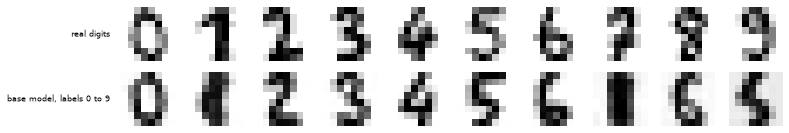

In [ ]:
ten = torch.arange(10)
real = torch.stack([test_x[test_y == k][0] for k in range(10)])
show_rows([real, sample(base, ten, seed=5)], ["real digits", "base model, labels 0 to 9"])
for k in (6, 7, 8, 9):
    got = torch.bincount(reads(sample(base, torch.full((100,), k), seed=3)), minlength=10)
    print(f"asked for {k}: the judge reads", got.tolist(), "(counts for the digits 0 to 9)")

The base model draws the digits it has seen. Asked for a 7, 8 or 9 it draws something else: the knowledge is not in the weights, and no prompt can add it. That is the case for fine-tuning (lesson 1).

## 2. A LoRA written by hand

`LoRALinear` computes `W x + (alpha / r) B A x` with `W` frozen, `A` random and `B` zero; `LoRAConv` does the same for convolutions. `add_lora` freezes the model and puts a LoRA next to every chosen layer. `finetune` trains the full model, a LoRA, or only the row of the new label (textual inversion's cousin).

In [ ]:
class LoRALinear(nn.Module):
    def __init__(self, base, r, alpha=None):
        super().__init__()
        self.base, self.r = base, r
        self.scale = (alpha if alpha is not None else r) / r            # alpha / r
        self.mult = 1.0                                                 # extra factor for merging experiments (1 = as trained, 0 = the original model)
        self.A = nn.Parameter(torch.randn(r, base.in_features) / math.sqrt(base.in_features))    # r x in: random start
        self.B = nn.Parameter(torch.zeros(base.out_features, r))                                  # out x r: ZERO start, so the model begins unchanged
    def forward(self, x):
        return self.base(x) + self.mult * self.scale * (x @ self.A.T @ self.B.T)

class LoRAConv(nn.Module):                                              # the same idea for a convolution: a k x k convolution into r channels, then a 1 x 1 convolution out
    def __init__(self, base, r, alpha=None):
        super().__init__()
        self.base, self.r = base, r
        self.scale = (alpha if alpha is not None else r) / r
        self.mult = 1.0
        self.A = nn.Conv2d(base.in_channels, r, base.kernel_size, base.stride, base.padding, bias=False)
        self.B = nn.Conv2d(r, base.out_channels, 1, bias=False)
        nn.init.zeros_(self.B.weight)
    def forward(self, x):
        return self.base(x) + self.mult * self.scale * self.B(self.A(x))

def add_lora(model, r, target="all", alpha=None):
    """freeze the model and put a LoRA next to the chosen layers. target 'attn' = the attention projections only; 'all' = every linear layer and convolution"""
    for p in model.parameters():
        p.requires_grad_(False)
    todo = []
    for name, mod in model.named_modules():
        if isinstance(mod, (nn.Linear, nn.Conv2d)) and (target == "all" or "attentions" in name):
            todo.append((name, mod))
    for name, mod in todo:
        parent = model.get_submodule(name.rsplit(".", 1)[0]) if "." in name else model
        new = LoRALinear(mod, r, alpha) if isinstance(mod, nn.Linear) else LoRAConv(mod, r, alpha)
        setattr(parent, name.rsplit(".", 1)[-1], new)
    return [m for m in model.modules() if isinstance(m, (LoRALinear, LoRAConv))]

def set_mult(model, m):
    for mod in model.modules():
        if isinstance(mod, (LoRALinear, LoRAConv)):
            mod.mult = m

def lora_formula(model):
    """the parameter count of all LoRAs by formula: out x r + r x in for a linear layer, out x r + r x in x k x k for a convolution"""
    n = 0
    for mod in model.modules():
        if isinstance(mod, LoRALinear):
            n += mod.base.out_features * mod.r + mod.r * mod.base.in_features
        elif isinstance(mod, LoRAConv):
            k = mod.base.kernel_size[0] * mod.base.kernel_size[1]
            n += mod.base.out_channels * mod.r + mod.r * mod.base.in_channels * k
    return n

def finetune(method, imgs, labels, steps=400, lr=None, r=4, seed=1, batch=16, target="all"):
    """method: 'full' (every weight), 'lora' (a low-rank correction next to frozen weights), 'embed' (only the label row of the new class)"""
    torch.manual_seed(seed)
    m = copy.deepcopy(base)
    if method == "lora":
        add_lora(m, r, target)
    elif method == "embed":
        for p in m.parameters():
            p.requires_grad_(False)
        m.class_embedding.weight.requires_grad_(True)
        row = torch.zeros(11, 1); row[labels[0]] = 1.0
        m.class_embedding.weight.register_hook(lambda g: g * row)         # only the row of the new label may change
    lr = lr or {"full": 2e-4, "lora": 1e-3, "embed": 1e-2}[method]
    params = [p for p in m.parameters() if p.requires_grad]
    n_trainable = m.class_embedding.weight.shape[1] if method == "embed" else sum(p.numel() for p in params)      # the new label's row: 128 numbers
    opt = torch.optim.Adam(params, lr)
    m.train()
    for s in range(steps):
        i = torch.randint(0, len(imgs), (batch,))
        x0, y = imgs[i], labels[i]
        t = torch.randint(0, 1000, (batch,))
        eps = torch.randn_like(x0)
        loss = F.mse_loss(m(sched.add_noise(x0, eps, t), t, class_labels=y).sample, eps)
        opt.zero_grad(); loss.backward(); opt.step()
    m.eval()
    return m, n_trainable

def measure(m, new_train, n_trainable, name="", extra=""):
    """the numbers of one fine-tuned model: the new digit (reads as it, diversity, distance of each picture to the nearest training picture) and the old digits (reads, diversity, drift)"""
    new = sample(m, torch.full((100,), NEW_DIGIT), seed=3)
    new_fid = (reads(new) == NEW_DIGIT).float().mean().item()
    nn_dist = torch.cdist(new.flatten(1), new_train.flatten(1)).min(1).values.mean().item()
    old = sample(m, OLD_LABELS, seed=4)
    old_fid = (reads(old) == OLD_LABELS).float().mean().item()
    drift = (old - OLD_REF).flatten(1).norm(dim=1).mean().item()
    old_div = sum(diversity(old[OLD_LABELS == k]) for k in range(7)) / 7
    print(f"{name:22s} {n_trainable:>9,d} trainable | new digit: reads {new_fid:5.0%}, diversity {diversity(new):5.2f}, nearest training picture {nn_dist:5.2f} | old digits: reads {old_fid:5.0%}, diversity {old_div:5.2f}, drift {drift:5.2f}{extra}")
    return dict(new_fid=new_fid, nn=nn_dist, new_div=diversity(new), old_fid=old_fid, old_div=old_div, drift=drift, n=n_trainable)

OLD_REF = sample(base, OLD_LABELS, seed=4)                  # what the ORIGINAL model draws for the old digits (same noise): the reference for forgetting

In [ ]:
# a LoRA next to every linear layer and convolution of a copy of the base model: the count by formula against the real count
m = copy.deepcopy(base)
add_lora(m, 4, "all")
print("trainable numbers (rank 4, all layers):", f"{count(m, trainable=True):,d}", "- by formula:", f"{lora_formula(m):,d}", "- base model:", f"{count(base):,d}")
x, t, y = torch.randn(4, 1, 8, 8), torch.tensor([300] * 4), torch.tensor([3, 3, 5, 5])
with torch.no_grad():
    print("untrained LoRA against the base model, largest difference of the output:", (m.eval()(x, t, class_labels=y).sample - base(x, t, class_labels=y).sample).abs().max().item())

trainable numbers (rank 4, all layers): 62,504 - by formula: 62,504 - base model: 702,753
untrained LoRA against the base model, largest difference of the output: 0.0


## 3. Full fine-tuning against LoRA, on 20 sevens

Same data, same 400 updates. Read the table with lessons 1 and 2 in hand: all methods learn the 7; full fine-tuning forgets most; the attention-only LoRA may be too small.

original model                 0 trainable | new digit: reads    0%, diversity  4.91, nearest training picture  5.27 | old digits: reads   99%, diversity  3.96, drift  0.00
full fine-tuning         702,753 trainable | new digit: reads  100%, diversity  3.40, nearest training picture  1.74 | old digits: reads   40%, diversity  3.48, drift  3.57
LoRA all rank 1           15,626 trainable | new digit: reads  100%, diversity  3.53, nearest training picture  2.27 | old digits: reads   78%, diversity  3.95, drift  2.49
LoRA all rank 4           62,504 trainable | new digit: reads  100%, diversity  3.43, nearest training picture  2.09 | old digits: reads   70%, diversity  3.78, drift  2.74
LoRA attention rank 4      8,192 trainable | new digit: reads   88%, diversity  4.15, nearest training picture  2.85 | old digits: reads   80%, diversity  4.07, drift  2.41


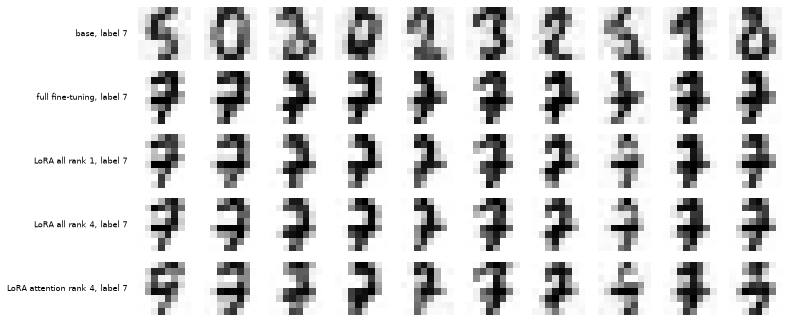

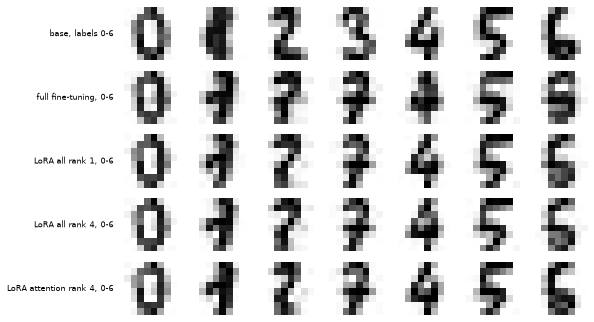

In [ ]:
new_all = train_x[train_y == NEW_DIGIT]
N = 20
imgs, labs = new_all[:N], torch.full((N,), NEW_DIGIT)
measure(base, imgs, 0, "original model")
runs = {}
for name, kw in (("full fine-tuning", dict(method="full")), ("LoRA all rank 1", dict(method="lora", r=1)), ("LoRA all rank 4", dict(method="lora", r=4)), ("LoRA attention rank 4", dict(method="lora", r=4, target="attn"))):
    m, n = finetune(imgs=imgs, labels=labs, **kw)
    runs[name] = (m, measure(m, imgs, n, name))
seven, old = torch.full((10,), 7), torch.arange(7)
show_rows([sample(base, seven, seed=6)] + [sample(m, seven, seed=6) for m, _ in runs.values()], ["base, label 7"] + [k + ", label 7" for k in runs])
show_rows([sample(base, old, seed=5)] + [sample(m, old, seed=5) for m, _ in runs.values()], ["base, labels 0-6"] + [k + ", 0-6" for k in runs])

## 4. The rank sweep

Trained numbers, old digits read correctly and drift for ranks 1 to 32 (all layers).

LoRA all rank 1           15,626 trainable | new digit: reads  100%, diversity  3.53, nearest training picture  2.27 | old digits: reads   78%, diversity  3.95, drift  2.49
LoRA all rank 2           31,252 trainable | new digit: reads   98%, diversity  3.77, nearest training picture  2.29 | old digits: reads   74%, diversity  3.86, drift  2.64
LoRA all rank 4           62,504 trainable | new digit: reads  100%, diversity  3.43, nearest training picture  2.09 | old digits: reads   70%, diversity  3.78, drift  2.74
LoRA all rank 8          125,008 trainable | new digit: reads  100%, diversity  3.50, nearest training picture  2.03 | old digits: reads   60%, diversity  3.73, drift  3.01
LoRA all rank 16         250,016 trainable | new digit: reads  100%, diversity  3.39, nearest training picture  1.98 | old digits: reads   53%, diversity  3.65, drift  3.19
LoRA all rank 32         500,032 trainable | new digit: reads   99%, diversity  3.43, nearest training picture  1.83 | old digits: read

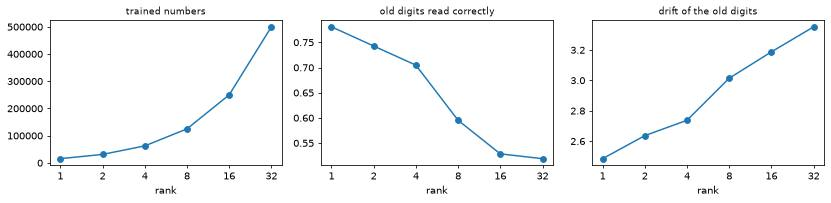

In [ ]:
RS = (1, 2, 4, 8, 16, 32)
sweep = {}
for r in RS:
    m, n = finetune("lora", imgs, labs, r=r)
    sweep[r] = measure(m, imgs, n, f"LoRA all rank {r}")
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a, k, title in zip(ax, ("n", "old_fid", "drift"), ("trained numbers", "old digits read correctly", "drift of the old digits")):
    a.plot(range(len(RS)), [sweep[r][k] for r in RS], "o-")
    a.set_xticks(range(len(RS))); a.set_xticklabels([str(r) for r in RS]); a.set_xlabel("rank"); a.set_title(title, fontsize=9)
plt.tight_layout(); plt.show()

## 5. The merge scale and merging

`set_mult` multiplies every LoRA correction: 0 is the original model, 1 the trained one. Then the correction is merged into the weights.

merge scale s: the layer computes W x + s B A x (s = 0 is the original model, s = 1 the trained one)
merge scale 0            125,008 trainable | new digit: reads    0%, diversity  4.91, nearest training picture  5.27 | old digits: reads   99%, diversity  3.96, drift  0.00
merge scale 0.25         125,008 trainable | new digit: reads   15%, diversity  4.97, nearest training picture  4.58 | old digits: reads   99%, diversity  3.96, drift  0.59
merge scale 0.5          125,008 trainable | new digit: reads   70%, diversity  4.48, nearest training picture  3.17 | old digits: reads   95%, diversity  3.95, drift  1.27
merge scale 0.75         125,008 trainable | new digit: reads   99%, diversity  3.82, nearest training picture  2.27 | old digits: reads   88%, diversity  3.86, drift  2.09
merge scale 1            125,008 trainable | new digit: reads  100%, diversity  3.50, nearest training picture  2.03 | old digits: reads   60%, diversity  3.73, drift  3.01
merge scale 1.5          125,008 t

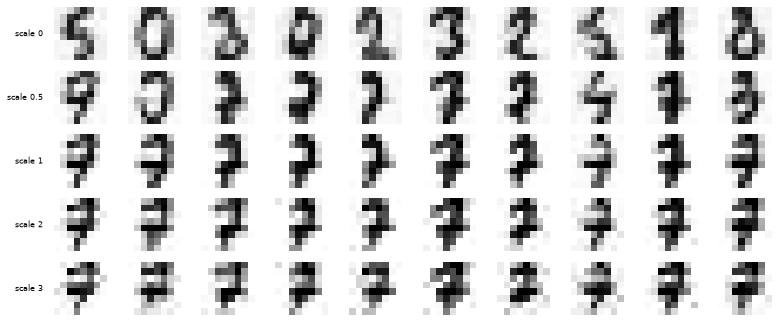

In [ ]:
m, n = finetune("lora", imgs, labs, r=8)
print("merge scale s: the layer computes W x + s B A x (s = 0 is the original model, s = 1 the trained one)")
for s in (0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0):
    set_mult(m, s)
    measure(m, imgs, n, f"merge scale {s:g}")
set_mult(m, 1.0)
show_rows([(set_mult(m, s), sample(m, seven, seed=6))[1] for s in (0.0, 0.5, 1.0, 2.0, 3.0)], [f"scale {s}" for s in (0, 0.5, 1, 2, 3)])
set_mult(m, 1.0)
with torch.no_grad():                                          # merging: put B A into the weights; the output stays the same
    y7 = torch.tensor([7] * 4)
    before = m(x, t, class_labels=y7).sample
    for mod in list(m.modules()):
        if isinstance(mod, LoRALinear):
            mod.base.weight += mod.scale * (mod.B @ mod.A); mod.B.zero_()
        elif isinstance(mod, LoRAConv):
            mod.base.weight += mod.scale * torch.einsum("or,rikl->oikl", mod.B.weight[:, :, 0, 0], mod.A.weight); mod.B.weight.zero_()
    print("after merging B A into the weights: largest difference of the output", f"{(before - m(x, t, class_labels=y7).sample).abs().max().item():.2e}")

## 6. Replay: the cheapest cure for forgetting

Mix 10 training pictures of each old digit into the fine-tuning set.

In [ ]:
old_pick = torch.cat([torch.nonzero(train_y == k).flatten()[:10] for k in range(7)])
mixed_imgs, mixed_labs = torch.cat([imgs, train_x[old_pick]]), torch.cat([labs, train_y[old_pick]])
for name, kw in (("full", dict(method="full")), ("LoRA all rank 4", dict(method="lora", r=4))):
    m, n = finetune(imgs=imgs, labels=labs, **kw); measure(m, imgs, n, f"{name}, sevens only")
    m, n = finetune(imgs=mixed_imgs, labels=mixed_labs, **kw); measure(m, imgs, n, f"{name}, with replay")

full, sevens only        702,753 trainable | new digit: reads  100%, diversity  3.40, nearest training picture  1.74 | old digits: reads   40%, diversity  3.48, drift  3.57
full, with replay        702,753 trainable | new digit: reads   94%, diversity  3.65, nearest training picture  2.40 | old digits: reads   95%, diversity  3.13, drift  2.39
LoRA all rank 4, sevens only    62,504 trainable | new digit: reads  100%, diversity  3.43, nearest training picture  2.09 | old digits: reads   70%, diversity  3.78, drift  2.74
LoRA all rank 4, with replay    62,504 trainable | new digit: reads   98%, diversity  3.75, nearest training picture  2.50 | old digits: reads   99%, diversity  3.47, drift  1.89


## 7. A real-photo version: a linear patch denoiser

The base denoiser is one 48 x 48 matrix (noisy 4 x 4 colour patch to clean patch) fitted on the china photo. It is adapted to the flower photo with `k` patches: the whole matrix against a rank-`r` correction `B A`. Tested on the right half of the flower photo and on a part of china (forgetting). The sample photos ship with scikit-learn.

In [ ]:
import math, torch
from sklearn.datasets import load_sample_image

def prep(name):
    return (torch.tensor(load_sample_image(name), dtype=torch.float32) / 127.5 - 1).permute(2, 0, 1)      # 3 x H x W, values -1 .. 1

def patches(im, p=4):                                                  # non-overlapping 4 x 4 x 3 patches, each as 48 numbers
    return im.unfold(1, p, p).unfold(2, p, p).permute(1, 2, 0, 3, 4).reshape(-1, 3 * p * p)

SIG = 0.5                                                               # noise added to every number (the pictures span -1 .. 1)
def noisy(P, seed):
    return P + SIG * torch.randn(P.shape, generator=torch.Generator().manual_seed(seed))
def psnr(a, b):
    return 10 * math.log10(4 / ((a - b) ** 2).mean().item())

china, flower = prep("china.jpg"), prep("flower.jpg")
Pc = patches(china)
Xc = noisy(Pc, 1)
W0 = torch.linalg.solve(Xc.T @ Xc + 1e-2 * torch.eye(48), Xc.T @ Pc).T                # BASE denoiser: one 48 x 48 matrix fitted on the china photo (noisy patch -> clean patch)
half = flower.shape[2] // 2
flower_train, flower_test, china_test = patches(flower[:, :, :half]), patches(flower[:, :, half:]), patches(china[:, :, 320:])
Tf, Tc = noisy(flower_test, 5), noisy(china_test, 6)
def test(W):
    return psnr(Tf @ W.T, flower_test), psnr(Tc @ W.T, china_test)
print(f"noisy patches of the flower test half: {psnr(Tf, flower_test):.2f} dB; base denoiser: flower {test(W0)[0]:.2f} dB, china {test(W0)[1]:.2f} dB (higher is better)")

def adapt(k, method, r=1, steps=300, seed=0):
    idx = torch.randperm(len(flower_train), generator=torch.Generator().manual_seed(seed))[:k]
    tr = flower_train[idx]
    torch.manual_seed(seed)
    if method == "full":
        W = W0.clone().requires_grad_(True); params, lr = [W], 3e-3
        get = lambda: W
    else:
        A = (torch.randn(r, 48) / math.sqrt(48)).requires_grad_(True); B = torch.zeros(48, r, requires_grad=True); params, lr = [A, B], 1e-2
        get = lambda: W0 + B @ A
    opt = torch.optim.Adam(params, lr)
    for _ in range(steps):
        x = tr + SIG * torch.randn_like(tr)
        loss = ((x @ get().T - tr) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
    W = get().detach()
    return W, sum(p.numel() for p in params), psnr((tr + SIG * torch.randn(tr.shape, generator=torch.Generator().manual_seed(9))) @ W.T, tr)

print("flower patches used  method        numbers trained   on the training patches   flower test   china test  (mean of 3 choices of the patches)")
for k in (5, 20, 100, 1000):
    for method, r in (("full", 0), ("lora", 1), ("lora", 2), ("lora", 4), ("lora", 8)):
        rows = [adapt(k, method, r, seed=s) for s in range(3)]
        tr_db = sum(x[2] for x in rows) / 3
        f = sum(test(x[0])[0] for x in rows) / 3
        c = sum(test(x[0])[1] for x in rows) / 3
        label = "full" if method == "full" else f"LoRA rank {r}"
        print(f"{k:19d}  {label:12s} {rows[0][1]:12,d} {tr_db:22.2f} dB {f:11.2f} dB {c:11.2f} dB")

noisy patches of the flower test half: 12.03 dB; base denoiser: flower 20.70 dB, china 21.77 dB (higher is better)
flower patches used  method        numbers trained   on the training patches   flower test   china test  (mean of 3 choices of the patches)
                  5  full                2,304                  26.18 dB       22.16 dB       20.24 dB
                  5  LoRA rank 1            96                  24.00 dB       22.16 dB       21.31 dB
                  5  LoRA rank 2           192                  23.68 dB       21.95 dB       21.12 dB
                  5  LoRA rank 4           384                  24.51 dB       21.88 dB       20.69 dB
                  5  LoRA rank 8           768                  25.62 dB       22.13 dB       20.60 dB
                 20  full                2,304                  23.58 dB       22.84 dB       20.44 dB
                 20  LoRA rank 1            96                  22.51 dB       22.41 dB       21.41 dB
                 20  LoR

## Try it yourself

1. In the comparison cell change `N = 20` to `5` and then to `100`. Which method overfits first (watch the distance to the nearest training picture)?
2. In the rank sweep find the smallest rank that reads the new digit in at least 95% of the pictures. Does forgetting grow with the rank in your run?
3. In the merge cell try `s = 5`. What do the pictures look like and what is the drift?
4. In the replay cell use 2 pictures per old digit instead of 10. How much of the protection is left?
5. Put the LoRA on the attention projections only (`target="attn"`) with rank 16. Compare the trained numbers and the new digit.
6. In the photo cell change the noise `SIG` to 0.3. Does the LoRA still win with 5 patches?
7. Change the learning rate of the full fine-tuning (`2e-4` in `finetune`) to `2e-5`. Does it forget less, and does it still learn the 7?